# Smart Irrigation — ML engineer notebook

**Постановка:** прогноз `sm_clean` на **24 / 72 / 168 годин** і бінарна класифікація потреби у поливі.

Це відтворювана **offline-оцінка на наявних файлах**, а не готовий контролер зрошення. Дані `hourly_model_table.csv`, `decision_labels_daily.csv` та `qa_drift.csv` із Data Engineering опису не були надані, тому перший прогін виконаний на `irrigation_ml_dataset.csv` із задокументованим евристичним очищенням. **Для класифікації використана лише демонстраційна мітка ризику низької вологості, а не підтверджена потреба в поливі.**

Завдання: побудувати чисті часові фолди, порівняти LightGBM з persistence, зафіксувати результат, підготувати серіалізовані моделі й аудиторські файли.


## 1. Конфігурація та завантаження артефактів

Запустіть `python -m pip install -r requirements.txt`. Щоб перенавчити все після заміни даних або отримання реальних міток від DE, поставте `RETRAIN=True`. Для виконання із завантаженими результатами достатньо `False`.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / 'ml_pipeline.py').exists():
    ROOT = Path('smart_irrigation_ml').resolve()
assert (ROOT / 'ml_pipeline.py').exists(), f'Project root not found: {ROOT}'
sys.path.insert(0, str(ROOT))

RETRAIN = False
if RETRAIN or not (ROOT / 'outputs' / 'run_summary.json').exists():
    from ml_pipeline import main
    main(root=str(ROOT))

with open(ROOT / 'outputs' / 'run_summary.json', encoding='utf8') as file:
    summary = json.load(file)
print('Dataset:', summary['data_quality']['input'])
print('Label source:', summary['classification_label_source'])
print('Actual irrigation labels?', summary['classification_is_real_irrigation'])

Dataset: /mnt/data/irrigation_ml_dataset.csv
Label source: DEMO_PROXY: next-day clean sensor moisture < 70.0; not actual irrigation need
Actual irrigation labels? False


## 2. Перевірка даних та очищення таргету

Початкова таблиця має 27 346 записів і 131 колонку для двох полів. Для кожного поля будується безперервний часовий індекс, а пропущені години лишаються `NaN`. Значення `sm_clean` не інтерполюються. Порогове правило `sm < 10` та розпізнавання тривалого залипання — **тимчасові інженерні припущення** до отримання фінальної очищеної вітрини. Прапорці довіри, зокрема `battery_voltage`, не видаляються.

,Параметр,Значення
0,Поля,2.00
1,Рядки джерела,27346.00
2,Погодинна сітка,27868.00
3,"Частка очищеного таргету, %",69.75
4,Позначено недостовірних значень,2674.00
5,Ознак ML,43.00


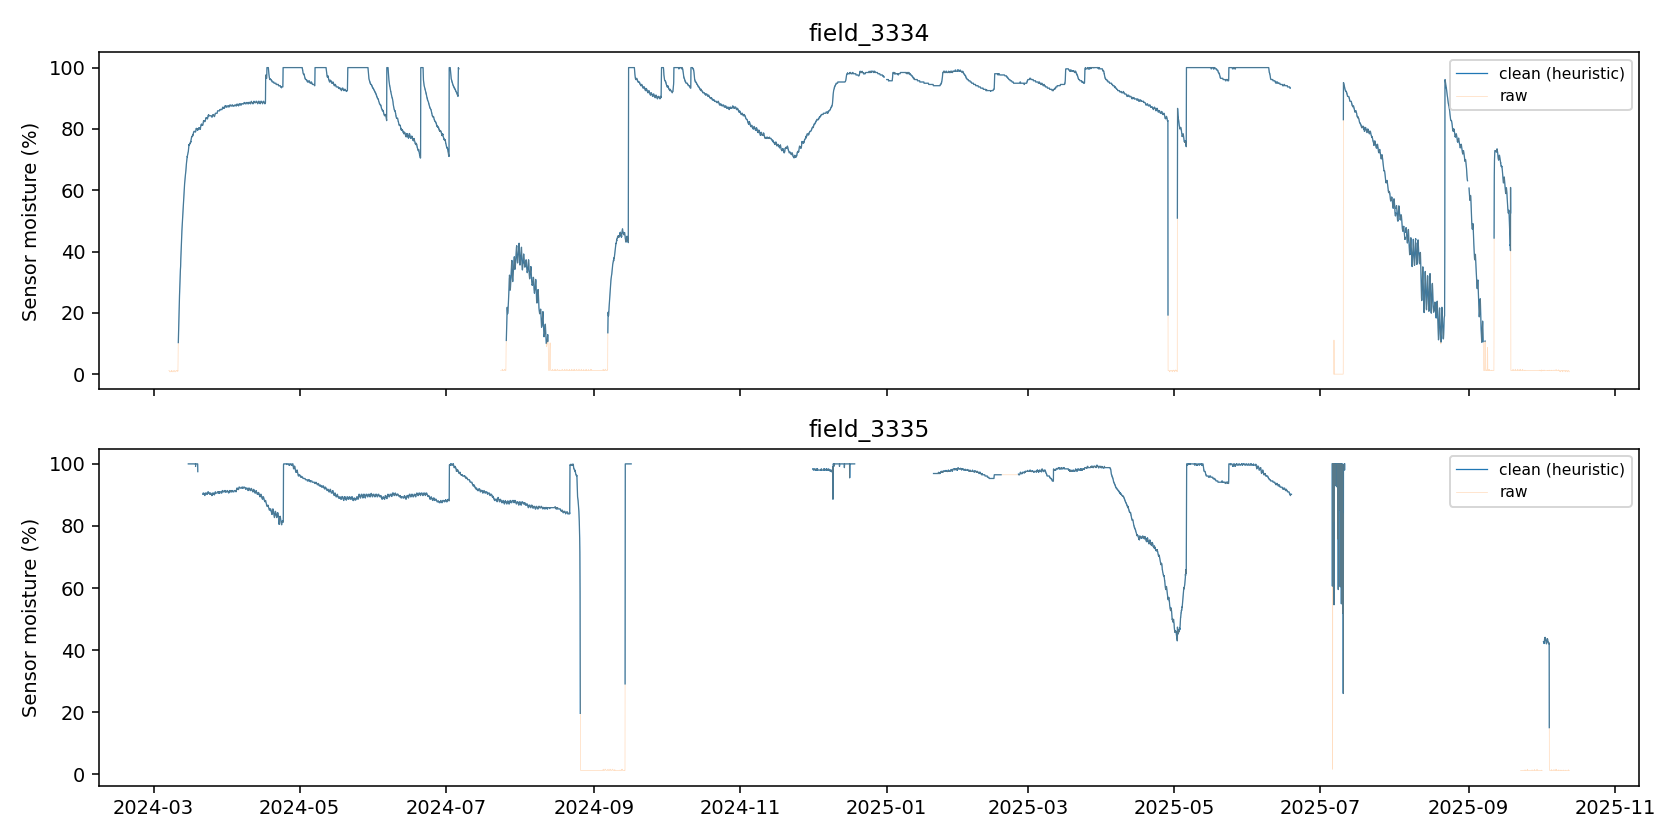

In [2]:
quality = summary['data_quality']
display(pd.DataFrame({
    'Параметр': ['Поля', 'Рядки джерела', 'Погодинна сітка', 'Частка очищеного таргету, %', 'Позначено недостовірних значень', 'Ознак ML'],
    'Значення': [quality['n_fields'], quality['raw_rows'], quality['full_hourly_rows'],
                 quality['clean_target_coverage_pct'], quality['bad_sensor_records'], quality['feature_count']]
}))
display(Image(filename=str(ROOT / 'figures' / 'sensor_cleaning.png')))

## 3. Регресія — розділення за часом і метрики

- `target_24h`, `target_72h`, `target_168h` = очищена вологість **рівно через H годин**.
- Ознаки: тільки історія та стан сенсорів на момент `t`: лаги 1/6/24/72/168 год, rolling mean, батарея, прапорці якості, температура, опади, сезонність. Без майбутньої погоди.
- Моделі: `lightgbm_level` прогнозує абсолютну вологість; `lightgbm_delta` прогнозує зміну від поточного рівня. Бейзлайн — `persistence`.
- Валідація: три walk-forward фолди в 2025 році із **purge gap = H** між train і test. `NaN` у таргеті не використовуються в loss.

**Критерій прийняття:** модель повинна покращувати MAE/RMSE відносно persistence на відкладених фолдах, а не лише мати хорошу абсолютну метрику.

In [3]:
fold_metrics = pd.read_csv(ROOT / 'outputs' / 'forecast_walkforward_metrics.csv')
pooled = pd.read_csv(ROOT / 'outputs' / 'forecast_pooled_comparison.csv')
display(fold_metrics.round(3))
print('Pooled results on the same out-of-fold timestamps:')
display(pooled.round(3).sort_values(['horizon_h', 'RMSE']))

for horizon in (24, 72, 168):
    r = pooled[pooled.horizon_h == horizon].sort_values('RMSE')
    best = r.iloc[0]
    print(f'{horizon}h: best by RMSE = {best.model}, RMSE={best.RMSE:.3f}, n={int(best.n)}')

,horizon_h,fold,model,n_train,n_test,MAE,RMSE
0,24,1,persistence,13769,3435,1.366,4.201
1,24,1,lightgbm_level,13769,3435,2.541,5.373
2,24,1,lightgbm_delta,13769,3435,3.445,7.496
3,24,2,persistence,17252,1047,2.721,6.153
4,24,2,lightgbm_level,17252,1047,6.331,9.920
5,24,2,lightgbm_delta,17252,1047,5.121,8.109
6,24,3,persistence,18347,671,6.876,15.577
7,24,3,lightgbm_level,18347,671,12.426,18.638
8,24,3,lightgbm_delta,18347,671,10.268,17.419
9,72,1,persistence,13372,3291,3.839,8.334


Pooled results on the same out-of-fold timestamps:


,horizon_h,model,MAE,RMSE,n
0,24,persistence,2.359,7.145,5153
2,24,lightgbm_level,4.598,9.191,5153
1,24,lightgbm_delta,4.674,9.504,5153
3,72,persistence,6.219,12.798,4686
4,72,lightgbm_delta,9.353,15.335,4686
5,72,lightgbm_level,10.078,16.776,4686
6,168,persistence,12.718,20.650,4176
7,168,lightgbm_delta,14.259,20.879,4176
8,168,lightgbm_level,15.841,23.105,4176


24h: best by RMSE = persistence, RMSE=7.145, n=5153
72h: best by RMSE = persistence, RMSE=12.798, n=4686
168h: best by RMSE = persistence, RMSE=20.650, n=4176


### Графіки прогнозу (тільки відкладені timestamps)

Вони показують причину, чому сліпе тренування складнішої моделі недостатнє: на тривалих стабільних ділянках проста persistence часто має меншу помилку, а в періоди дрейфу навчена модель може відставати.

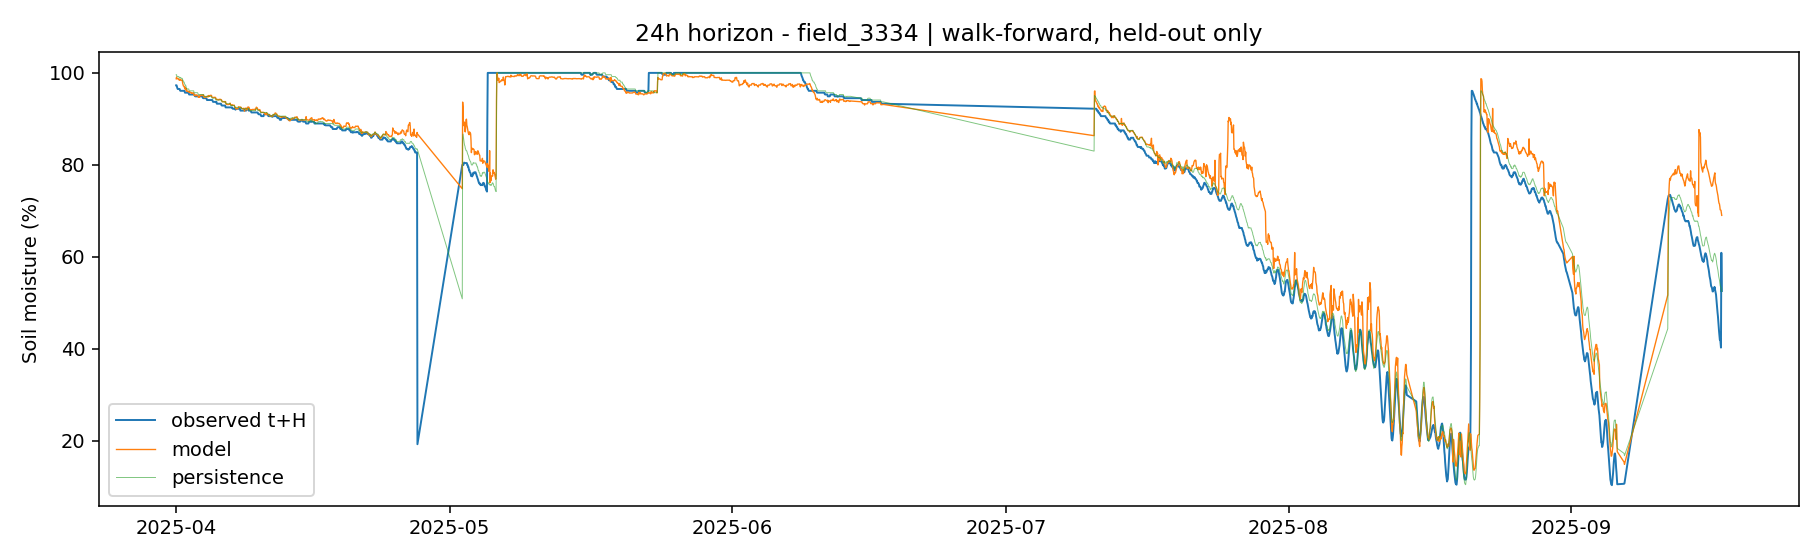

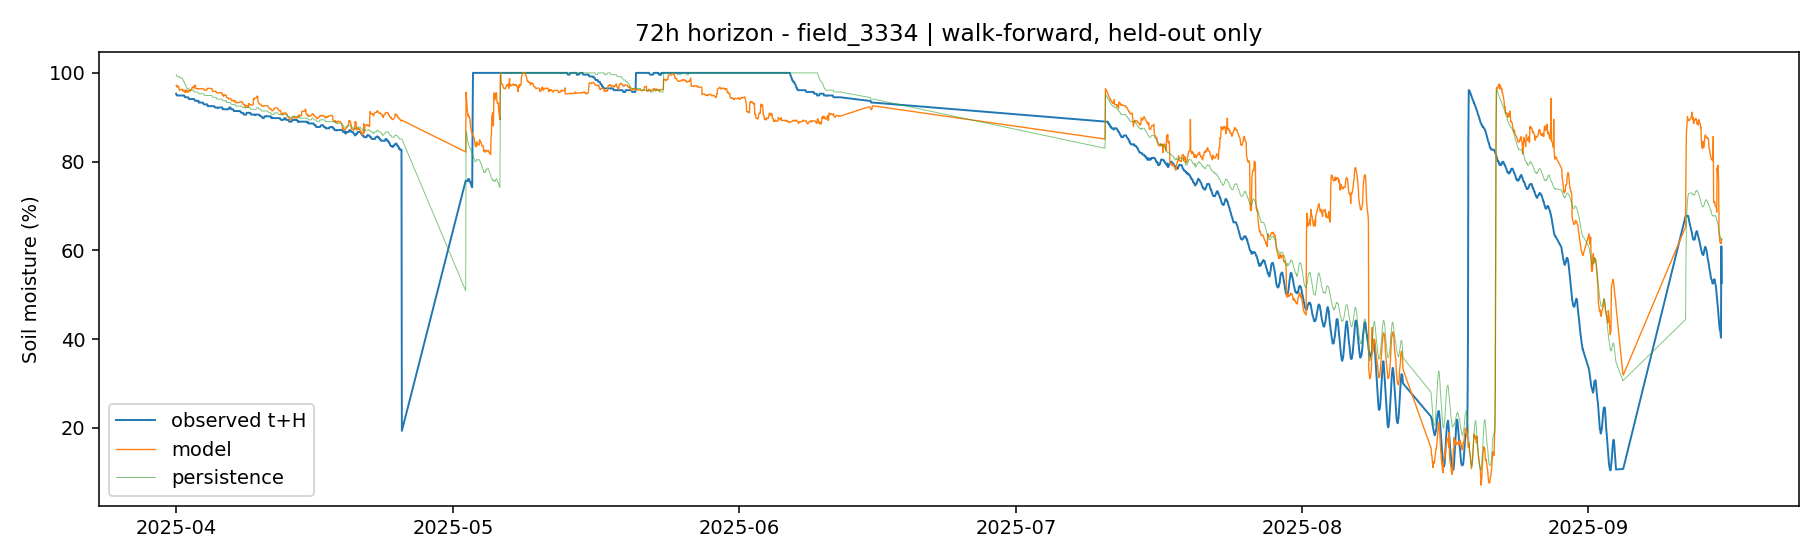

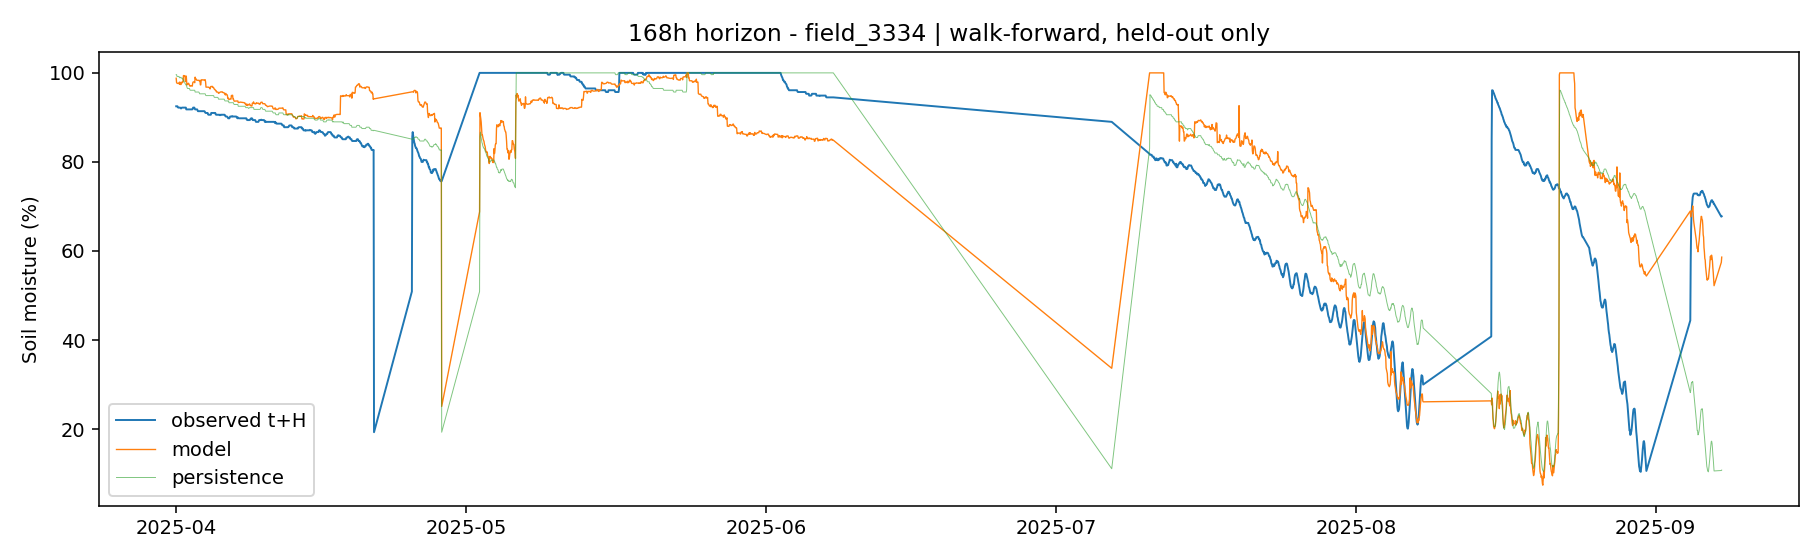

In [4]:
for horizon in (24, 72, 168):
    display(Image(filename=str(ROOT / 'figures' / f'forecast_{horizon}h.png')))

## 4. Класифікація — критична різниця між *міткою* та *потребою в поливі*

Для справжньої задачі рішення потрібні `daily_decision_table.csv` та `decision_labels_daily.csv` з підтвердженою міткою `irrigate / no_action / postpone` або бінарною колонкою. Відсутній файл **не вигадується**.

Поки його немає, тут навчена **демонстраційна** модель ризику: чи буде `sm_clean` через 24 години **нижче 70** на шкалі сенсора. Поріг 70 умовний, це **не агрономічний поріг поливу**. Такі результати не можна видавати за метрики рекомендації зрошення.

Модель: `LightGBMClassifier`, класам надані ваги; поріг імовірності калібрується на останній частині train із пріоритетом **F2 / Recall**, не на test. Показуємо F1, Recall, Precision, PR-AUC і False Negatives.

УВАГА: класифікатор оцінено лише на DEMO_PROXY мітках.
DEMO_PROXY: next-day clean sensor moisture < 70.0; not actual irrigation need


,fold,status,n_train,n_test,positive_train,positive_test,threshold,F1,Recall,Precision,F2,PR_AUC,FN,FP
0,1,OK,583,144,28,11,0.50,0.375,0.273,0.60,0.306,0.651,8,2
1,2,OK,729,46,39,19,0.15,0.923,0.947,0.90,0.938,0.995,1,2
2,3,OK,777,32,58,21,0.15,0.909,0.952,0.87,0.935,0.899,1,3


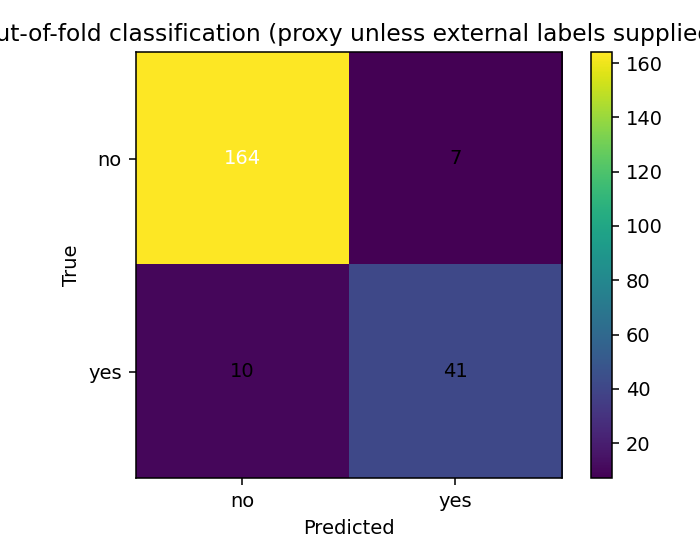

Інтерпретація: пропуск випадку низької вологості, НЕ поливу


In [5]:
if summary['classification_is_real_irrigation']:
    print('Використано зовнішні мітки. Перевірте, чи вони спостережені або симульовані за FAO-56.')
else:
    print('УВАГА: класифікатор оцінено лише на DEMO_PROXY мітках.')
cls_metrics = pd.read_csv(ROOT / 'outputs' / 'classification_walkforward_metrics.csv')
print(summary['classification_label_source'])
display(cls_metrics.round(3))
display(Image(filename=str(ROOT / 'figures' / 'classification_confusion.png')))
print('Інтерпретація:', 'мітка із завантаженого джерела' if summary['classification_is_real_irrigation'] else 'пропуск випадку низької вологості, НЕ поливу')

## 5. Зсув розподілів / drift

Без `qa_drift.csv` ми **не можемо** заявляти про отримані DE-тести Кендалла або CUSUM. Наводимо власний описовий зсув медіан між 2024 / початком 2025 та тестовим періодом із 2025-04-01. Для продакшену потрібен моніторинг за полем і періодичне перенавчання.

In [6]:
drift = pd.read_csv(ROOT / 'outputs' / 'drift_train_vs_test.csv')
display(drift.round(3))

,feature,field_id,train_median,test_median,difference,n_train,n_test
0,sm_clean,field_3334,93.3,87.35,-5.95,8143,3338
1,sm_clean,field_3335,92.2,94.10,1.90,5878,2078
2,battery_voltage,field_3334,4.1,4.10,0.00,8896,4220
3,battery_voltage,field_3335,4.1,4.10,0.00,6499,2496
4,air_temperature_sensor,field_3334,11.6,17.90,6.30,8896,4122
5,air_temperature_sensor,field_3335,16.5,15.20,-1.30,6189,2387
6,soil_temperature_sensor,field_3334,12.0,21.00,9.00,8896,4123
7,soil_temperature_sensor,field_3335,19.0,16.00,-3.00,6193,2432


## 6. Демонстрація inference

Моделі `*.joblib` зберігають точний список ознак. Нижче зчитується реальна остання **валідна** телеметрична точка кожного поля. Це лише показ механіки прогнозу; якщо останній надійний вимір старий, такий прогноз **не є актуальним**. Offline persistence має нижчу RMSE за ML на наданих фолдах, тому його слід тримати як baseline/безпечний варіант, поки ML не перевершить його.

In [7]:
import joblib
from ml_pipeline import load_hourly, make_features

src = Path(summary['data_quality']['input'])
if not src.exists():
    src = next((p for p in [ROOT/'input'/'hourly_model_table.parquet', ROOT/'input'/'hourly_model_table.csv', ROOT/'input'/'irrigation_ml_dataset.csv'] if p.exists()), src)
if src.exists():
    d, _ = load_hourly(src)
    features_df, all_features = make_features(d)
    latest = (features_df[features_df.sm_clean.notna()]
              .sort_values('timestamp').groupby('field_id').tail(1))
    examples = []
    for horizon in (24, 72, 168):
        pkg = joblib.load(ROOT / 'models' / f'soil_moisture_{horizon}h_delta.joblib')
        y_delta = pkg['model'].predict(latest[pkg['features']])
        pred = np.clip(latest.sm_clean.to_numpy() + y_delta, 0, 100)
        for (_, item), value in zip(latest.iterrows(), pred):
            examples.append({'field_id': item.field_id, 'issued_at': item.timestamp,
                             'horizon_h': horizon, 'current_moisture': item.sm_clean,
                             'lgbm_prediction': float(value), 'persistence': item.sm_clean})
    display(pd.DataFrame(examples).round(2))
else:
    print('Source CSV not found after moving the package. Put original CSV in input/ and rerun.')

,field_id,issued_at,horizon_h,current_moisture,lgbm_prediction,persistence
0,field_3334,2025-09-18 12:00:00,24,52.6,46.64,52.6
1,field_3335,2025-10-04 15:00:00,24,15.0,24.95,15.0
2,field_3334,2025-09-18 12:00:00,72,52.6,49.35,52.6
3,field_3335,2025-10-04 15:00:00,72,15.0,59.47,15.0
4,field_3334,2025-09-18 12:00:00,168,52.6,85.77,52.6
5,field_3335,2025-10-04 15:00:00,168,15.0,66.66,15.0


## 7. Підсумок і наступні кроки перед здачею

1. **Виконано:** відтворюваний forecasting для 24/72/168 год, ML-моделі, бейзлайн, 3 часові фолди, аудит пропусків, діагностика drift, серіалізовані результати.
2. **Проміжний результат:** persistence кращий за обидва LightGBM-варианти на сумарних відкладених помилках. ML-рішення не можна обирати лише через складність алгоритму.
3. **Демонстрація класифікації:** бінарний пайплайн працює, але оцінка на сурогатних мітках **не доводить**, що рекомендації про полив точні.
4. **Потрібно від Data Engineering:** справжні `hourly_model_table.csv`, `daily_decision_table.csv`, `decision_labels_daily.csv`, `qa_drift.csv`, `ref_*.csv`, бажано Parquet. У hourly вітрині повинні залишитися `battery_voltage` і прапорці аномалій.
5. **Перед використанням на полі:** погодинно валідована історія вимірів, незалежна оцінка на іншому полі, агрономічно підтверджені мітки, актуальні прогнозні метеодані, правила safe fallback та моніторинг drift.

Артефакти доступні в `outputs/`, `models/`, `figures/` і `training_log.txt`.